<a href="https://colab.research.google.com/github/anupbagale/python-for-ai-ml/blob/main/18-computer-vision/01_lesson.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Module 18: Computer Vision

Computer vision is about getting useful information out of images: what's in a photo, where it is, whether a scan shows something unusual. It's also where deep learning first proved itself. In 2012 a convolutional neural network won the ImageNet competition by a wide margin, and within a few years almost every vision system in use was built the same way.

In Module 17 you trained an MLP on photos of clothing. It worked, but it treated each image as a list of 784 unrelated numbers. This module introduces the **convolution**, an operation built for images, and the **convolutional neural network (CNN)** made from it. You'll write convolutions by hand, train a CNN, help it cope with shifted and varied pictures using **data augmentation**, and then use a network trained by someone else on more than a million photos, which is how most real vision projects start.

**Contents**

1. Images as numbers
2. Convolution by hand
3. Padding, stride and channels
4. Pooling
5. Why convolutions work for images
6. A CNN in PyTorch
7. What a CNN learns
8. Moving the picture
9. Data augmentation
10. Deeper networks and residual connections
11. Pretrained models
12. Transfer learning
13. Beyond classification

In [1]:
import gzip
import time
import urllib.request
from pathlib import Path

import numpy as np
import torch
import torch.nn.functional as F
import torchvision
from skimage import data as sample_images
from sklearn.linear_model import LogisticRegression
from torch import nn
from torch.utils.data import DataLoader, Dataset, TensorDataset
from torchvision.transforms import v2

print("PyTorch", torch.__version__, "  torchvision", torchvision.__version__)
_ = torch.manual_seed(0)

PyTorch 2.15.0+cu132   torchvision 0.29.2+cu132


In [2]:
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

# Categorical colours, always used in this order. The first three are checked to stay
# distinguishable for the common forms of colour blindness, even in scatter plots.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]

SURFACE = "#fcfcfb"     # chart background
INK = "#0b0b0b"         # titles and important text
INK_2 = "#52514e"       # labels and tick text
MUTED = "#898781"       # de-emphasised marks
GRID = "#e1e0d9"        # gridlines
AXIS = "#c3c2b7"        # axis lines

# Sequential: one hue, light to dark, for magnitude (heatmaps, counts)
SEQUENTIAL = LinearSegmentedColormap.from_list(
    "course_blues", ["#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])
# Diverging: two opposite hues with a neutral grey in the middle, for values around zero
DIVERGING = LinearSegmentedColormap.from_list(
    "course_diverging", ["#184f95", "#86b6ef", "#f0efec", "#f0a3a2", "#c23a3a"])


def use_course_style():
    for cmap in (SEQUENTIAL, DIVERGING):
        if cmap.name not in mpl.colormaps:
            mpl.colormaps.register(cmap)
    mpl.rcParams.update({
        "figure.facecolor": SURFACE,
        "axes.facecolor": SURFACE,
        "savefig.facecolor": SURFACE,
        "figure.dpi": 100,
        "savefig.dpi": 150,
        "figure.figsize": (7, 4),
        "font.size": 10,
        "text.color": INK,
        "axes.titlesize": 12,
        "axes.titleweight": "bold",
        "axes.titlelocation": "left",
        "axes.titlepad": 10,
        "axes.labelcolor": INK_2,
        "axes.edgecolor": AXIS,
        "axes.linewidth": 0.8,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "axes.axisbelow": True,
        "grid.color": GRID,
        "grid.linewidth": 0.8,
        "grid.linestyle": "-",
        "xtick.color": AXIS,
        "ytick.color": AXIS,
        "xtick.labelcolor": INK_2,
        "ytick.labelcolor": INK_2,
        "axes.prop_cycle": mpl.cycler(color=PALETTE),
        "lines.linewidth": 1.6,
        "lines.solid_capstyle": "round",
        "lines.markersize": 6,
        "patch.linewidth": 0,
        "legend.frameon": False,
        "legend.labelcolor": INK_2,
        "image.cmap": "course_blues",
    })


use_course_style()

PyTorch, torchvision (PyTorch's library for images) and scikit-image all come pre-installed on Google Colab. On your own computer: `pip install torch torchvision scikit-image`.

The lesson runs on an ordinary CPU in about three minutes. The first run also downloads Fashion-MNIST (about 30 MB) and a pretrained network (about 45 MB).

## 1. Images as numbers

A colour image is a grid of pixels, and each pixel has three numbers: how much **red**, **green** and **blue** light it has, usually from 0 to 255. So a colour photo is a three-dimensional array. Here's a photo that comes with scikit-image:

shape: (400, 600, 3)   dtype: uint8   values from 0 to 255
the pixel at row 100, column 200 (red, green, blue): [203 143  85]


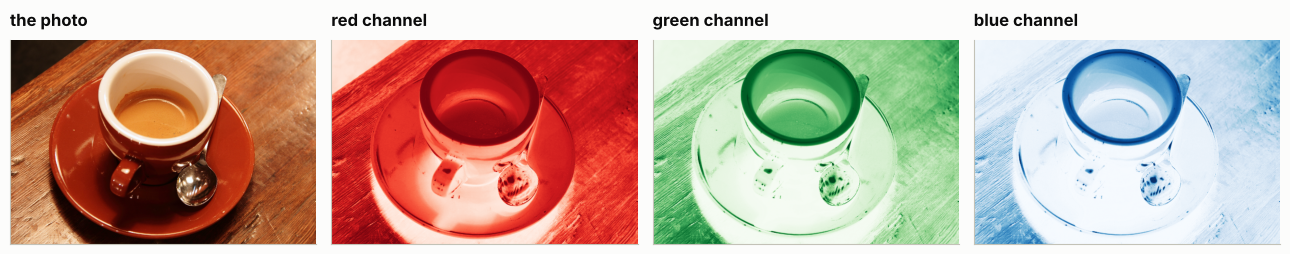

In [3]:
coffee = sample_images.coffee()
print("shape:", coffee.shape, "  dtype:", coffee.dtype, "  values from", coffee.min(), "to", coffee.max())
print("the pixel at row 100, column 200 (red, green, blue):", coffee[100, 200])

fig, axes = plt.subplots(1, 4, figsize=(13, 2.9))
axes[0].imshow(coffee)
axes[0].set_title("the photo")
for ax, c, name, cmap in zip(axes[1:], range(3), ["red", "green", "blue"], ["Reds", "Greens", "Blues"]):
    ax.imshow(coffee[:, :, c], cmap=cmap, vmin=0, vmax=255)
    ax.set_title(f"{name} channel")
for ax in axes:
    ax.set_xticks([])
    ax.set_yticks([])
    ax.grid(False)
plt.tight_layout()
plt.show()

The photo is 400 pixels high, 600 wide, with 3 **channels**. Each channel on its own is a greyscale image: the red channel is bright where the photo has a lot of red, like the saucer's rim.

Libraries disagree about the order of the dimensions. Images loaded with NumPy, scikit-image or Pillow are **(height, width, channels)**. PyTorch wants **(channels, height, width)**, and a batch of images is **(batch, channels, height, width)**, usually written `(N, C, H, W)`. Networks also want floating-point numbers on a small scale, not integers up to 255:

In [4]:
x = torch.from_numpy(coffee).permute(2, 0, 1).float() / 255     # (H, W, C) uint8 -> (C, H, W) float in [0, 1]
batch = x.unsqueeze(0)                                           # add a batch dimension
print("one image:", tuple(x.shape), "  a batch of one:", tuple(batch.shape))

one image: (3, 400, 600)   a batch of one: (1, 3, 400, 600)


## 2. Convolution by hand

A **convolution** slides a small grid of weights, called a **kernel** or **filter**, across the image. At each position it multiplies the kernel by the patch of pixels underneath and adds everything up. The result is a new image, sometimes called a **feature map**, that's bright wherever the patch matched the kernel well.

Here it is in plain NumPy, for one greyscale image and one kernel:

In [5]:
def convolve2d(image, kernel):
    """Slide the kernel over the image (no padding, stride 1) and return the map of weighted sums."""
    kh, kw = kernel.shape
    out_h, out_w = image.shape[0] - kh + 1, image.shape[1] - kw + 1
    out = np.zeros((out_h, out_w))
    for i in range(out_h):
        for j in range(out_w):
            out[i, j] = np.sum(image[i:i + kh, j:j + kw] * kernel)
    return out


tiny = np.array([[0, 0, 0, 9, 9],
                 [0, 0, 0, 9, 9],
                 [0, 0, 0, 9, 9],
                 [0, 0, 0, 9, 9]], dtype=float)
vertical_edge = np.array([[-1, 0, 1],
                          [-1, 0, 1],
                          [-1, 0, 1]], dtype=float)
print(convolve2d(tiny, vertical_edge))

[[ 0. 27. 27.]
 [ 0. 27. 27.]]


The kernel subtracts the column on its left from the column on its right, so it gives 0 on flat areas and a large number where dark changes to bright: it's a **vertical edge detector**. The 4 x 5 image became a 2 x 3 map, because a 3 x 3 kernel only fits in 2 x 3 positions.

Different kernels find different things. Here are four classic hand-designed ones applied to a photo of a cat, Chelsea, also from scikit-image:

four convolutions with Python loops: 2.5 seconds


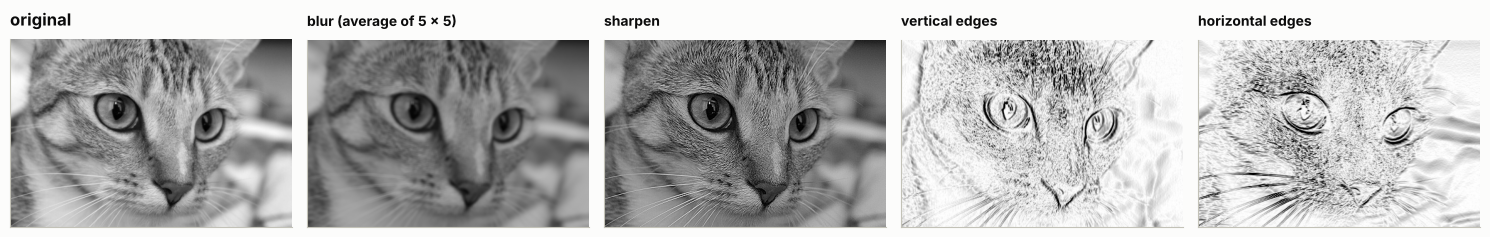

In [6]:
cat = sample_images.chelsea().mean(axis=2) / 255               # greyscale, values from 0 to 1

kernels = {
    "blur (average of 5 x 5)": np.ones((5, 5)) / 25,
    "sharpen": np.array([[0, -1, 0], [-1, 5, -1], [0, -1, 0]], dtype=float),
    "vertical edges": np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], dtype=float),
    "horizontal edges": np.array([[-1, -2, -1], [0, 0, 0], [1, 2, 1]], dtype=float),
}

start = time.time()
results = {name: convolve2d(cat, k) for name, k in kernels.items()}
print(f"four convolutions with Python loops: {time.time() - start:.1f} seconds")

fig, axes = plt.subplots(1, 5, figsize=(15, 2.9))
axes[0].imshow(cat, cmap="gray")
axes[0].set_title("original")
for ax, (name, result) in zip(axes[1:], results.items()):
    if "edges" in name:
        strength = np.abs(result)
        ax.imshow(strength, cmap="gray_r", vmin=0, vmax=np.percentile(strength, 99))   # dark = strong edge
    else:
        ax.imshow(result, cmap="gray", vmin=0, vmax=1)
    ax.set_title(name, fontsize=10)
for ax in axes:
    ax.set_xticks([])
    ax.set_yticks([])
    ax.grid(False)
plt.tight_layout()
plt.show()

The blur averages each pixel with its neighbours. Sharpen does the opposite, exaggerating the difference between a pixel and its neighbours. The two edge detectors (called **Sobel** filters) respond to vertical edges, like the stripes on the forehead and the sides of the nose, and to horizontal ones, like the whiskers and the top and bottom of the eyes.

The Python loops are slow, and a network computes millions of these sums. PyTorch's `F.conv2d` does the same arithmetic with fast compiled code. It expects batches: the image as `(N, C, H, W)` and the kernels as `(out_channels, in_channels, kH, kW)`:

In [7]:
image_t = torch.tensor(cat, dtype=torch.float32).reshape(1, 1, *cat.shape)
kernel_t = torch.tensor(kernels["vertical edges"], dtype=torch.float32).reshape(1, 1, 3, 3)

start = time.time()
torch_result = F.conv2d(image_t, kernel_t)
print(f"F.conv2d: {(time.time() - start) * 1000:.1f} milliseconds,  output shape {tuple(torch_result.shape)}")
print("same answer as the loops:", np.allclose(torch_result[0, 0].numpy(), results["vertical edges"], atol=1e-5))

F.conv2d: 3.9 milliseconds,  output shape (1, 1, 298, 449)
same answer as the loops: True


A small note on names: mathematicians define convolution with the kernel **flipped** before sliding, and what we computed (no flip) is called **cross-correlation**. Deep learning libraries all compute cross-correlation and call it convolution. Since the network learns its kernels, it makes no difference: it simply learns the flipped version.

The big idea of a CNN is that **the network learns its own kernels**. Instead of designing an edge detector by hand, you start with random numbers and let gradient descent find kernels that are useful for the task.

## 3. Padding, stride and channels

**Padding** adds a border of zeros around the image before sliding the kernel, so the output can keep the input's size. **Stride** is how far the kernel moves at each step: stride 2 skips every other position and halves the size. For an input of size `n`, a kernel of size `k`, padding `p` and stride `s`, the output size is

$$\left\lfloor \frac{n + 2p - k}{s} \right\rfloor + 1$$

In [8]:
x = torch.randn(1, 1, 28, 28)
for k, p, s in [(3, 0, 1), (3, 1, 1), (5, 2, 1), (3, 1, 2), (7, 3, 2)]:
    out = F.conv2d(x, torch.randn(1, 1, k, k), padding=p, stride=s)
    formula = (28 + 2 * p - k) // s + 1
    print(f"kernel {k}, padding {p}, stride {s}: output {out.shape[-2]} x {out.shape[-1]}   (formula: {formula})")

kernel 3, padding 0, stride 1: output 26 x 26   (formula: 26)
kernel 3, padding 1, stride 1: output 28 x 28   (formula: 28)
kernel 5, padding 2, stride 1: output 28 x 28   (formula: 28)
kernel 3, padding 1, stride 2: output 14 x 14   (formula: 14)
kernel 7, padding 3, stride 2: output 14 x 14   (formula: 14)


A 3 x 3 kernel with padding 1 keeps the size the same, which is why it's the most common choice.

Real images have several channels, and a convolution layer produces several. Each output channel has its own kernel **for every input channel**: it convolves each input channel with its own small grid, then adds the results together (plus one bias). So the weights of a convolution layer have shape `(out_channels, in_channels, k, k)`:

In [9]:
conv = nn.Conv2d(in_channels=3, out_channels=16, kernel_size=3, padding=1)
print("weight shape:", tuple(conv.weight.shape), "  bias shape:", tuple(conv.bias.shape))
print("parameters:", sum(p.numel() for p in conv.parameters()), "= 16 x 3 x 3 x 3 weights + 16 biases")
print("coffee photo:", tuple(batch.shape), "->", tuple(conv(batch).shape))

weight shape: (16, 3, 3, 3)   bias shape: (16,)
parameters: 448 = 16 x 3 x 3 x 3 weights + 16 biases
coffee photo: (1, 3, 400, 600) -> (1, 16, 400, 600)


16 output channels means 16 different feature maps, each looking for a different pattern in all three colour channels at once. The next layer then treats those 16 maps as its input channels, and combines them into patterns of patterns.

## 4. Pooling

A **pooling** layer shrinks a feature map by summarising small blocks. **Max pooling** with a 2 x 2 window keeps the largest value in each block, halving the height and width:

In [10]:
fm = torch.tensor([[1., 3, 2, 0],
                   [4, 2, 1, 1],
                   [0, 1, 5, 6],
                   [2, 2, 7, 3]]).reshape(1, 1, 4, 4)
print(F.max_pool2d(fm, kernel_size=2)[0, 0])
print(F.avg_pool2d(fm, kernel_size=2)[0, 0])

tensor([[4., 2.],
        [2., 7.]])
tensor([[2.5000, 1.0000],
        [1.2500, 5.2500]])


Pooling does three useful things. It **reduces the amount of computation** in later layers. It makes the network a little **less sensitive to exact positions**: if a feature moves by one pixel within a block, the maximum is often the same. And it lets later layers **see more of the image**.

That last point has a name: the **receptive field** of a unit is the patch of the input image that can affect it. One 3 x 3 convolution sees 3 x 3 pixels. Stack two and each unit of the second layer sees 5 x 5 pixels; put a 2 x 2 pooling between them and it sees 8 x 8. Early layers see small patches and find edges and spots; deep layers see most of the image and can respond to whole objects.

## 5. Why convolutions work for images

Compare a convolution layer with a fully connected layer on a 28 x 28 image, both producing 16 feature maps of the same size:

In [11]:
conv_layer = nn.Conv2d(1, 16, kernel_size=3, padding=1)
dense_layer = nn.Linear(28 * 28, 16 * 28 * 28)
print(f"convolution:     {sum(p.numel() for p in conv_layer.parameters()):>12,} parameters")
print(f"fully connected: {sum(p.numel() for p in dense_layer.parameters()):>12,} parameters")

convolution:              160 parameters
fully connected:    9,847,040 parameters


160 parameters against nearly 10 million. Two assumptions about images make this possible:

- **Locality.** A pixel is mostly related to its neighbours, so each output only needs to look at a small patch.
- **Weight sharing.** An edge is an edge wherever it appears, so the **same** kernel is used at every position.

Weight sharing gives convolutions a useful property called **translation equivariance**: move the input, and the feature map moves the same way. Here we shift the cat photo 30 pixels to the right and run the edge detector on both versions:

In [12]:
shifted = np.zeros_like(cat)
shifted[:, 30:] = cat[:, :-30]

edges = convolve2d(cat, kernels["vertical edges"])
edges_shifted = convolve2d(shifted, kernels["vertical edges"])
same = np.allclose(edges_shifted[:, 32:], edges[:, 2:-30])
print("the edge map of the shifted photo is the shifted edge map:", same)

the edge map of the shifted photo is the shifted edge map: True


Apart from the strip at the left edge, the two maps are identical, just shifted. An MLP has no such property: it has separate weights for every pixel, so a pattern it learnt in one place means nothing to it in another. We'll test that on real data in Section 8.

## 6. A CNN in PyTorch

Now a real network, on Fashion-MNIST from Module 17. We use the same split as there: 50,000 training images and 10,000 for validation. The files are downloaded once and saved in `data/fashion_mnist/`.

In [13]:
SOURCE = "https://raw.githubusercontent.com/zalandoresearch/fashion-mnist/master/data/fashion/"
FOLDER = Path("data") / "fashion_mnist"
FILES = ["train-images-idx3-ubyte.gz", "train-labels-idx1-ubyte.gz"]
FOLDER.mkdir(parents=True, exist_ok=True)
for name in FILES:
    if not (FOLDER / name).exists():
        print("downloading", name)
        urllib.request.urlretrieve(SOURCE + name, FOLDER / name)


def read_idx(path):
    with gzip.open(path, "rb") as f:
        raw = f.read()
    n_dims = raw[3]
    shape = [int.from_bytes(raw[4 + 4 * i: 8 + 4 * i], "big") for i in range(n_dims)]
    return np.frombuffer(raw, dtype=np.uint8, offset=4 + 4 * n_dims).reshape(shape)


images, labels = read_idx(FOLDER / FILES[0]), read_idx(FOLDER / FILES[1])
CLASSES = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat", "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]

order = np.random.default_rng(0).permutation(len(images))
train_idx, valid_idx = order[:50_000], order[50_000:]
pixels = torch.from_numpy(images.copy()).unsqueeze(1)          # (60000, 1, 28, 28), uint8: CNNs keep the 2D layout
MEAN = pixels[train_idx].float().mean().item() / 255
STD = pixels[train_idx].float().std().item() / 255


def to_input(x_uint8):
    return (x_uint8.float() / 255 - MEAN) / STD


X_train, X_valid = to_input(pixels[train_idx]), to_input(pixels[valid_idx])
y_train, y_valid = torch.from_numpy(labels[train_idx].astype(np.int64)), torch.from_numpy(labels[valid_idx].astype(np.int64))
print("training batch shape:", tuple(X_train.shape), "  validation:", tuple(X_valid.shape))

training batch shape: (50000, 1, 28, 28)   validation: (10000, 1, 28, 28)


Unlike the MLP, the network gets each image as a 1 x 28 x 28 grid, not a flat list. The architecture is the classic pattern: a few **blocks** of convolution, batch normalisation, ReLU and max pooling, each halving the image size and doubling the number of channels, then a final linear layer.

In [14]:
def conv_block(c_in, c_out):
    return [nn.Conv2d(c_in, c_out, kernel_size=3, padding=1, bias=False),   # no bias: batch norm adds its own shift
            nn.BatchNorm2d(c_out), nn.ReLU(), nn.MaxPool2d(2)]


def small_cnn():
    return nn.Sequential(*conv_block(1, 16), *conv_block(16, 32), *conv_block(32, 64),
                         nn.Flatten(), nn.Linear(64 * 3 * 3, 10))


cnn = small_cnn()
x = X_train[:1]
print(f"{'input':<12}{str(tuple(x.shape)):>18}")
for layer in cnn:
    x = layer(x)
    if not isinstance(layer, (nn.BatchNorm2d, nn.ReLU)):
        print(f"{type(layer).__name__:<12}{str(tuple(x.shape)):>18}")
print(f"\nparameters: {sum(p.numel() for p in cnn.parameters()):,}")

input           (1, 1, 28, 28)
Conv2d         (1, 16, 28, 28)
MaxPool2d      (1, 16, 14, 14)
Conv2d         (1, 32, 14, 14)
MaxPool2d        (1, 32, 7, 7)
Conv2d           (1, 64, 7, 7)
MaxPool2d        (1, 64, 3, 3)
Flatten               (1, 576)
Linear                 (1, 10)

parameters: 29,178


The image shrinks from 28 x 28 to 14, 7 and 3 (pooling rounds down), while the channels grow from 1 to 16, 32 and 64. At the end, each image is 64 x 3 x 3 = 576 numbers describing which patterns appear roughly where, and a linear layer turns those into 10 class scores.

The training and evaluation functions are the ones from Module 17. We train the CNN for 4 epochs, and for comparison an MLP like Module 17's for 5:

In [15]:
def train(model, loader, epochs, lr=1e-3, every=1):
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    start = time.time()
    for epoch in range(epochs):
        model.train()
        for xb, yb in loader:
            optimizer.zero_grad()
            F.cross_entropy(model(xb), yb).backward()
            optimizer.step()
        if every and (epoch + 1) % every == 0:
            print(f"  epoch {epoch + 1}: validation accuracy {accuracy(model, X_valid, y_valid):.3f}   ({time.time() - start:.0f} s)")
    return model


@torch.no_grad()
def accuracy(model, X, y, batch_size=1000):
    model.eval()
    correct = sum((model(X[i:i + batch_size]).argmax(dim=1) == y[i:i + batch_size]).sum().item()
                  for i in range(0, len(X), batch_size))
    return correct / len(X)


def loader(X, y, batch_size=128, seed=0):
    return DataLoader(TensorDataset(X, y), batch_size=batch_size, shuffle=True,
                      generator=torch.Generator().manual_seed(seed))


print("CNN")
torch.manual_seed(0)
cnn = train(small_cnn(), loader(X_train, y_train), epochs=4)

print("MLP")
torch.manual_seed(0)
mlp = nn.Sequential(nn.Flatten(), nn.Linear(784, 256), nn.ReLU(), nn.Linear(256, 128), nn.ReLU(), nn.Linear(128, 10))
mlp = train(mlp, loader(X_train, y_train), epochs=5)
print(f"\nparameters: CNN {sum(p.numel() for p in cnn.parameters()):,}, MLP {sum(p.numel() for p in mlp.parameters()):,}")

CNN


  epoch 1: validation accuracy 0.870   (16 s)


  epoch 2: validation accuracy 0.896   (31 s)


  epoch 3: validation accuracy 0.899   (46 s)


  epoch 4: validation accuracy 0.902   (62 s)
MLP


  epoch 1: validation accuracy 0.853   (1 s)


  epoch 2: validation accuracy 0.871   (3 s)


  epoch 3: validation accuracy 0.873   (4 s)


  epoch 4: validation accuracy 0.883   (5 s)


  epoch 5: validation accuracy 0.886   (6 s)

parameters: CNN 29,178, MLP 235,146


The CNN is ahead of the MLP after fewer epochs, with about one eighth of the parameters. It also does about as well as the regularised MLP in Module 17's mini project, which needed 30 epochs and over half a million parameters.

The CNN's epochs take much longer, though. Each of its parameters is used at every position of the image, so it does far more arithmetic per parameter than an MLP. That's the trade-off convolutions make: **few parameters, lots of computation**, which is exactly what graphics cards are good at.

## 7. What a CNN learns

The first layer's 16 kernels are 3 x 3 grids of weights that operate directly on pixels, so we can draw them. Below them are the 16 feature maps they produce for one training image:

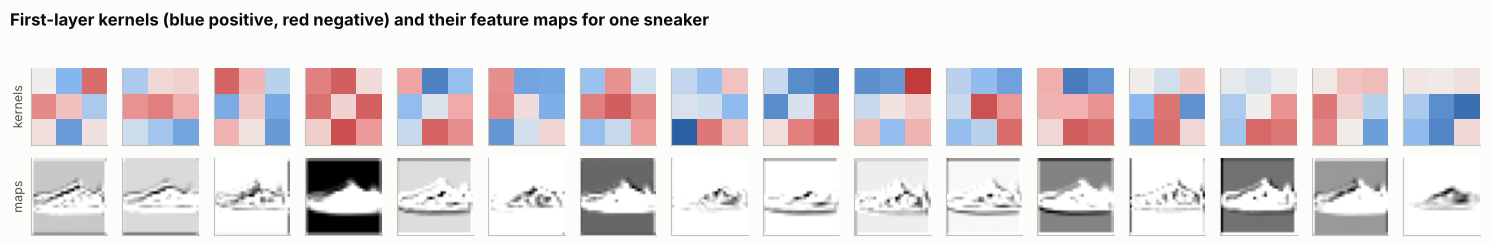

In [16]:
first_conv = cnn[0]
weights = first_conv.weight.detach()[:, 0]                       # (16, 3, 3)
example = X_train[:1]
with torch.no_grad():
    maps = cnn[2](cnn[1](first_conv(example)))[0]               # conv -> batch norm -> ReLU: (16, 28, 28)

fig, axes = plt.subplots(2, 16, figsize=(15, 2.6))
limit = weights.abs().max()
for k in range(16):
    axes[0, k].imshow(weights[k], cmap=DIVERGING.reversed(), vmin=-limit, vmax=limit)
    axes[1, k].imshow(maps[k], cmap="gray_r")
for ax in axes.flat:
    ax.set_xticks([])
    ax.set_yticks([])
    ax.grid(False)
axes[0, 0].set_ylabel("kernels", fontsize=9)
axes[1, 0].set_ylabel("maps", fontsize=9)
fig.suptitle(f"First-layer kernels (blue positive, red negative) and their feature maps for one {CLASSES[y_train[0]].lower()}",
             x=0.01, ha="left", fontweight="bold", fontsize=12)
plt.tight_layout()
plt.show()

Nobody told the network to look for edges, yet many of its kernels have a positive side and a negative side, like the hand-made edge detectors in Section 2, and their feature maps light up along particular outlines of the item. Others respond to the item's overall brightness or to its background. The same thing happens in much bigger networks trained on photos: the first layer learns edge and colour detectors, the next layers combine them into textures and parts, and the deepest layers respond to whole objects.

## 8. Moving the picture

Fashion-MNIST images are all neatly centred. What happens if the items are shifted a few pixels to the right? We shift the validation images (filling the gap with background) and test both networks again:

In [17]:
def shift_right(X, pixels):
    """Shift images right by some pixels, filling the gap on the left with the background value."""
    if pixels == 0:
        return X
    out = torch.full_like(X, to_input(torch.zeros(1)).item())     # the value a black pixel has after scaling
    out[..., pixels:] = X[..., :-pixels]
    return out


print(f"{'shift':>6}{'CNN':>8}{'MLP':>8}")
shift_results = {"CNN": [], "MLP": []}
for s in range(5):
    Xs = shift_right(X_valid, s)
    shift_results["CNN"].append(accuracy(cnn, Xs, y_valid))
    shift_results["MLP"].append(accuracy(mlp, Xs, y_valid))
    print(f"{s:>6}{shift_results['CNN'][-1]:>8.3f}{shift_results['MLP'][-1]:>8.3f}")

 shift     CNN     MLP


     0   0.902   0.886


     1   0.879   0.811


     2   0.798   0.538


     3   0.671   0.352


     4   0.531   0.262


Both networks get worse, because neither ever saw a shifted item during training. But the MLP collapses: a shift of 3 pixels cuts its accuracy to around a third, because its weights are tied to exact pixel positions. The CNN degrades much more gracefully, thanks to its shared kernels and pooling. It's not fully immune, though. Its final linear layer still sees a 3 x 3 grid of positions, and shifted items fall in different cells of that grid.

If we expect shifted items in real use, the fix is to show the network shifted items during training.

## 9. Data augmentation

**Data augmentation** creates new training examples by changing the existing ones in ways that don't change the answer: a T-shirt shifted two pixels or mirrored left to right is still a T-shirt. Each epoch, every image is changed randomly, so the network never sees exactly the same picture twice.

torchvision's `transforms.v2` module provides the common transformations. They're applied one image at a time, inside a `Dataset`:

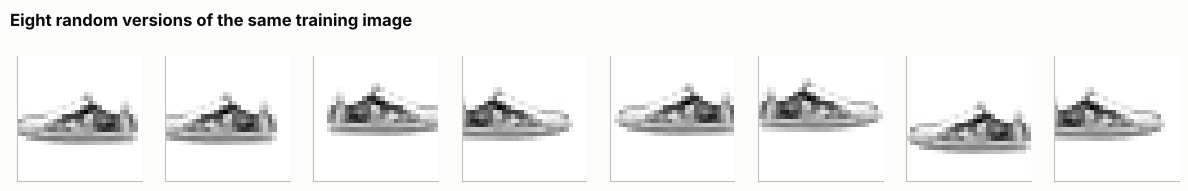

In [18]:
class AugmentedImages(Dataset):
    def __init__(self, pixels, labels, transform=None):
        self.pixels, self.labels, self.transform = pixels, labels, transform

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, i):
        x = self.pixels[i]                                      # (1, 28, 28) uint8
        if self.transform is not None:
            x = self.transform(x)                               # a new random version every time
        return to_input(x), self.labels[i]


flip = v2.RandomHorizontalFlip()
flip_and_shift = v2.Compose([v2.RandomHorizontalFlip(), v2.RandomCrop(28, padding=3)])   # pad with black, crop back to 28 x 28

torch.manual_seed(1)
demo = AugmentedImages(pixels[train_idx[:1]], y_train[:1], flip_and_shift)
fig, axes = plt.subplots(1, 8, figsize=(12, 1.9))
for ax in axes:
    ax.imshow(demo[0][0][0], cmap="gray_r")
    ax.set_xticks([])
    ax.set_yticks([])
    ax.grid(False)
fig.suptitle("Eight random versions of the same training image", x=0.01, ha="left", fontweight="bold", fontsize=12)
plt.tight_layout()
plt.show()

Augmentation matters most when training data is scarce, so we use only **1,000** training images. We train the same CNN three times, with no augmentation, with random flips, and with random flips and shifts of up to 3 pixels, and test each on the normal validation images and on a version where every image has been randomly shifted by up to 3 pixels:

In [19]:
small = train_idx[np.random.default_rng(1).choice(len(train_idx), 1000, replace=False)]
y_small = torch.from_numpy(labels[small].astype(np.int64))

torch.manual_seed(5)
valid_shifted = torch.stack([to_input(v2.RandomCrop(28, padding=3)(pixels[i])) for i in valid_idx])

augmentation_results = {}
for name, transform in [("no augmentation", None), ("flips", flip), ("flips and shifts", flip_and_shift)]:
    torch.manual_seed(0)
    model = small_cnn()
    data_loader = DataLoader(AugmentedImages(pixels[small], y_small, transform), batch_size=64, shuffle=True,
                             generator=torch.Generator().manual_seed(0))
    start = time.time()
    train(model, data_loader, epochs=50, every=0)
    augmentation_results[name] = (accuracy(model, X_valid, y_valid), accuracy(model, valid_shifted, y_valid))
    print(f"{name:<18} centred validation {augmentation_results[name][0]:.3f}   "
          f"shifted validation {augmentation_results[name][1]:.3f}   ({time.time() - start:.0f} s)")

no augmentation    centred validation 0.845   shifted validation 0.674   (18 s)


flips              centred validation 0.846   shifted validation 0.678   (19 s)


flips and shifts   centred validation 0.807   shifted validation 0.791   (23 s)


Read the two columns separately:

- **On the shifted images**, the network trained with shifts is far better than the others. It learnt that an item can sit anywhere in the frame, because it was shown items everywhere.
- **On the centred images**, augmentation with shifts doesn't help and costs a few points: those validation images are never shifted, so the network spent part of its effort on a variation that never comes up.
- **Flips** make little difference either way. Fashion-MNIST items are photographed facing the same way, so a mirrored item is plausible but adds little new information.

This is the main rule of augmentation: **mimic the variation you expect when the model is used**. If real photos will be taken at different angles, in different light, partly cut off, or off-centre, augment for those. Don't augment in ways that change the answer: flipping a 6 upside down makes a 9, and flipping a photo of text makes it unreadable. For photos, the usual augmentations are random crops and rescaling, flips, small rotations and changes of brightness and colour.

Augmentation is applied only to training data. Validation and test images are used as they are.

## 10. Deeper networks and residual connections

The history of image classification is largely a history of going deeper:

| year | network | layers | idea |
|---|---|---|---|
| 1998 | LeNet-5 | 7 | convolution and pooling, for reading handwritten digits on cheques |
| 2012 | AlexNet | 8 | the same idea, much bigger, trained on GPUs with ReLU and dropout |
| 2014 | VGG | 16 to 19 | only 3 x 3 convolutions, stacked deep |
| 2015 | ResNet | 18 to 152 | **residual connections**, which made very deep networks trainable |

Simply stacking more layers stops helping after about 20: the networks get harder to train, and even their training error gets worse. ResNet's fix is simple. Each **residual block** computes a correction and **adds it to its input**, instead of replacing the input:

$$\text{output} = \text{ReLU}\big(x + F(x)\big)$$

where `F` is two convolutions. If a block has nothing useful to add, it only has to learn `F(x) = 0`, and the input passes through unchanged. The additions also give gradients a direct path back through the network, past every block.

In [20]:
class ResidualBlock(nn.Module):
    def __init__(self, channels):
        super().__init__()
        self.conv1 = nn.Conv2d(channels, channels, 3, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(channels)
        self.conv2 = nn.Conv2d(channels, channels, 3, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(channels)

    def forward(self, x):
        correction = self.bn2(self.conv2(F.relu(self.bn1(self.conv1(x)))))
        return F.relu(x + correction)                           # the skip connection


block = ResidualBlock(32)
print("input", tuple(torch.randn(2, 32, 14, 14).shape), "-> output", tuple(block(torch.randn(2, 32, 14, 14)).shape))

input (2, 32, 14, 14) -> output (2, 32, 14, 14)


The output has the same shape as the input, which the addition requires. When a block changes the number of channels or the image size, the shortcut gets a 1 x 1 convolution to match the shapes (Exercise 11 asks you to build that version).

torchvision includes the standard architectures. Here is ResNet-18, the smallest ResNet, built without any trained weights:

In [21]:
resnet = torchvision.models.resnet18(weights=None)
for name, child in resnet.named_children():
    n = sum(p.numel() for p in child.parameters())
    print(f"{name:<8} {type(child).__name__:<18} {n:>12,} parameters")
print(f"{'total':<27} {sum(p.numel() for p in resnet.parameters()):>12,}")

conv1    Conv2d                    9,408 parameters
bn1      BatchNorm2d                 128 parameters
relu     ReLU                          0 parameters
maxpool  MaxPool2d                     0 parameters
layer1   Sequential              147,968 parameters
layer2   Sequential              525,568 parameters
layer3   Sequential            2,099,712 parameters
layer4   Sequential            8,393,728 parameters
avgpool  AdaptiveAvgPool2d             0 parameters
fc       Linear                  513,000 parameters
total                         11,689,512


A 7 x 7 convolution and a max pooling shrink the image quickly, then four stages (`layer1` to `layer4`) of two residual blocks each, then **global average pooling** (`avgpool`), which averages each of the 512 final feature maps down to one number whatever the image size, and a linear layer (`fc`) with 1,000 outputs. More than 11 million parameters, most of them in the last stage.

## 11. Pretrained models

Training a network like ResNet-18 well takes over a million labelled photos and many hours of GPU time. Fortunately you rarely need to: networks **pretrained** on the **ImageNet** dataset (about 1.3 million photos in 1,000 classes, from goldfish to garbage trucks) are freely available. torchvision downloads the weights on first use:

In [22]:
weights = torchvision.models.ResNet18_Weights.IMAGENET1K_V1
pretrained = torchvision.models.resnet18(weights=weights).eval()
preprocess = weights.transforms()                    # the exact preprocessing used in training
imagenet_classes = weights.meta["categories"]
print(preprocess)
print(f"{len(imagenet_classes)} classes, for example: {imagenet_classes[1]}, {imagenet_classes[285]}, {imagenet_classes[569]}")

ImageClassification(
    crop_size=[224]
    resize_size=[256]
    mean=[0.485, 0.456, 0.406]
    std=[0.229, 0.224, 0.225]
    interpolation=InterpolationMode.BILINEAR
)
1000 classes, for example: goldfish, Egyptian cat, garbage truck


A pretrained model only works properly with **the same preprocessing it was trained with**: resize so the shorter side is 256 pixels, cut out the central 224 x 224, scale to [0, 1], and standardise each colour channel with ImageNet's mean and standard deviation. The weights come with this recipe, so there's no need to remember it.

Let's ask the network about five pictures that come with scikit-image: the coffee from Section 1, the cat, a rocket launch, a drawing of a horse's silhouette, and a Hubble telescope photo of distant galaxies:

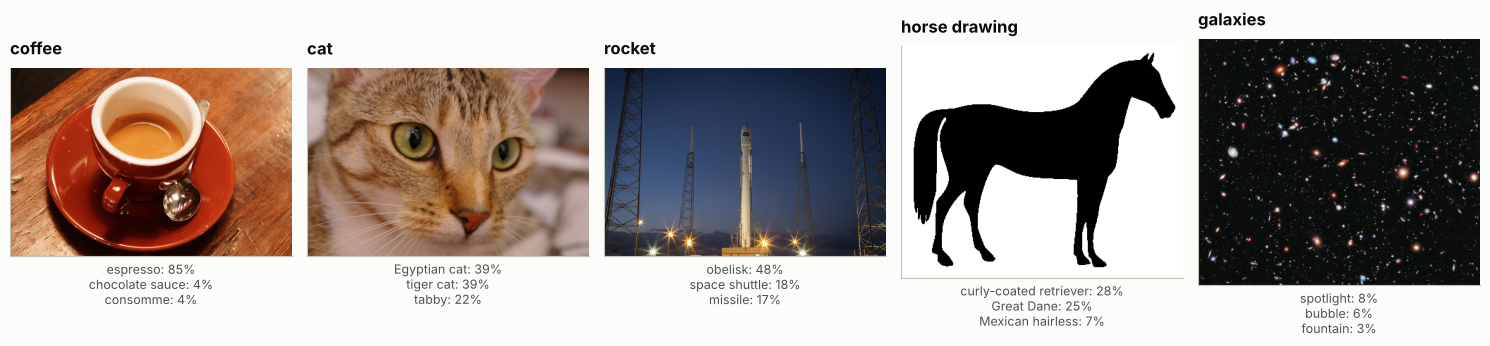

In [23]:
def as_rgb_tensor(img):
    """A NumPy image (greyscale, boolean or colour) as a (3, H, W) uint8 tensor."""
    img = np.asarray(img)
    if img.dtype == bool:
        img = np.where(img, 255, 0).astype(np.uint8)          # True is the background: white, with a black horse
    if img.ndim == 2:
        img = np.stack([img] * 3, axis=-1)
    return torch.from_numpy(np.ascontiguousarray(img[..., :3])).permute(2, 0, 1)


pictures = {"coffee": sample_images.coffee(), "cat": sample_images.chelsea(), "rocket": sample_images.rocket(),
            "horse drawing": sample_images.horse(), "galaxies": sample_images.hubble_deep_field()}

fig, axes = plt.subplots(1, 5, figsize=(15, 4.4))
for ax, (name, img) in zip(axes, pictures.items()):
    x = as_rgb_tensor(img)
    with torch.no_grad():
        probabilities = torch.softmax(pretrained(preprocess(x).unsqueeze(0)), dim=1)[0]
    top = probabilities.topk(3)
    ax.imshow(x.permute(1, 2, 0).numpy())
    ax.set_xticks([])
    ax.set_yticks([])
    ax.grid(False)
    ax.set_title(name)
    ax.set_xlabel("\n".join(f"{imagenet_classes[i]}: {p:.0%}" for p, i in zip(top.values.tolist(), top.indices.tolist())), fontsize=9)
plt.tight_layout()
plt.show()

On the first three, the network does well: an espresso, a cat (split between three of ImageNet's cat breeds, which is reasonable for a tabby), and for the rocket a sensible mix of tall pointed objects, including space shuttle and missile.

The last two show the limits:

- **It can only answer with its 1,000 classes.** ImageNet has no "galaxy", so the network picks the least bad of the classes it knows, and spreads its probability thinly.
- **It's only reliable on pictures like the ones it was trained on.** ImageNet is photographs. A black-and-white silhouette is a different kind of image, and the network sees a dog where a person sees a horse.

A low top probability can be a hint that something is wrong, but it's not a guarantee: networks can be confidently wrong on unusual inputs.

## 12. Transfer learning

ImageNet's 1,000 classes probably don't include what you care about: types of rubbish, plant diseases, defects on a production line. But the network's **features**, the 512 numbers that come out of global average pooling, describe edges, textures, shapes and parts that are useful for almost any photo. **Transfer learning** reuses them:

- **Feature extraction.** Freeze the pretrained network, remove its last layer, and train only a new last layer (or any simple classifier, such as logistic regression) on the 512 features. Fast, and works with very little data.
- **Fine-tuning.** Start from the pretrained weights, replace the last layer, and keep training some or all of the network on your data with a small learning rate. Usually more accurate, but slower, and needs a bit more data to avoid overfitting.

In PyTorch, freezing means setting `requires_grad = False`, and replacing the last layer means assigning a new `nn.Linear`:

In [24]:
model = torchvision.models.resnet18(weights=weights)
for p in model.parameters():
    p.requires_grad = False                           # freeze everything
model.fc = nn.Linear(model.fc.in_features, 6)         # a new, trainable last layer for 6 classes


def trainable(m):
    return sum(p.numel() for p in m.parameters() if p.requires_grad)


print(f"feature extraction: {trainable(model):>10,} trainable parameters")
for p in model.layer4.parameters():
    p.requires_grad = True                            # fine-tune the last stage too
print(f"fine-tuning layer4: {trainable(model):>10,} trainable parameters")

feature extraction:      3,078 trainable parameters
fine-tuning layer4:  8,396,806 trainable parameters


Then pass only the trainable parameters to the optimiser, for example `torch.optim.AdamW(p for p in model.parameters() if p.requires_grad)`. Two more details matter when fine-tuning: use a **smaller learning rate** for the pretrained layers than for the new one, so the useful features aren't wrecked in the first few steps, and remember that batch normalisation layers update their running statistics in training mode even when their weights are frozen.

Transfer learning works best when your images resemble the ones the network was trained on. As a check, here are ImageNet features against a small CNN trained from scratch on just **500** Fashion-MNIST images. The tiny grey images are scaled up to 64 x 64 and copied into three colour channels so ResNet-18 can read them:

In [25]:
backbone = torchvision.models.resnet18(weights=weights).eval()
backbone.fc = nn.Identity()                          # output the 512 features instead of 1,000 scores
imagenet_mean = torch.tensor(weights.transforms().mean).view(1, 3, 1, 1)
imagenet_std = torch.tensor(weights.transforms().std).view(1, 3, 1, 1)


@torch.no_grad()
def resnet_features(idx):
    out = []
    for i in range(0, len(idx), 250):
        x = pixels[idx[i:i + 250]].float() / 255
        x = F.interpolate(x, size=64, mode="bilinear", align_corners=False).expand(-1, 3, -1, -1)
        out.append(backbone((x - imagenet_mean) / imagenet_std))
    return torch.cat(out).numpy()


few = train_idx[np.random.default_rng(2).choice(len(train_idx), 500, replace=False)]
check = valid_idx[:2000]
start = time.time()
features = LogisticRegression(max_iter=2000).fit(resnet_features(few), labels[few])
print(f"ImageNet features + logistic regression: {features.score(resnet_features(check), labels[check]):.3f}   ({time.time() - start:.0f} s)")

torch.manual_seed(0)
start = time.time()
scratch = train(small_cnn(), loader(to_input(pixels[few]), torch.from_numpy(labels[few].astype(np.int64)), batch_size=32),
                epochs=60, every=0)
scratch_acc = accuracy(scratch, to_input(pixels[check]), torch.from_numpy(labels[check].astype(np.int64)))
print(f"small CNN trained from scratch:          {scratch_acc:.3f}   ({time.time() - start:.0f} s)")

ImageNet features + logistic regression: 0.775   (5 s)


small CNN trained from scratch:          0.793   (10 s)


Here the pretrained features give no real advantage. Edges and shapes from colour photographs aren't much use for tiny, blurry, greyscale pictures of clothing, and a small network trained directly on the task does about as well. That's worth remembering: **transfer learning is a strong default for photos, not magic for every kind of image**.

The mini project shows the other side: real photos of rubbish to be sorted for recycling, a few hundred per class, where a pretrained network is far ahead of anything we could train from scratch in the same time.

## 13. Beyond classification

Classification answers "what's in this image?". The same building blocks power other vision tasks:

- **Object detection** finds every object and draws a box around it: "two people and a bicycle, here, here and here". Used in self-driving cars, wildlife cameras and shop checkouts. torchvision has pretrained detectors such as Faster R-CNN.
- **Semantic segmentation** labels every pixel: road, pavement, car, sky. Medical imaging uses it to outline organs and tumours. Networks such as U-Net are shaped like an hourglass, shrinking the image to find what's there and growing it back to say exactly where.
- **Image similarity and search**: the pretrained features from Section 12 can be compared with cosine similarity (Module 16) to find similar images.
- **Vision transformers** use attention, the subject of Module 19, instead of convolutions. With enough data they match or beat CNNs, and they're the basis of models that connect images and text.

A few practical points for your own projects:

- **Start with a pretrained network.** Train from scratch only if your images are very different from photos and you have plenty of them.
- **Use the right preprocessing**, the same as in training, and augment only the training data.
- **Look at your data** and at your model's mistakes. Vision models are notorious for learning shortcuts, such as a watermark, a background or a ruler that happens to appear in one class's photos.
- **Use a GPU** for anything bigger than this lesson. On Colab: Runtime > Change runtime type > GPU, then move the model and every batch to the device, as in Module 17.

## Summary

- An image is an array of pixels: `(H, W, C)` in most libraries, `(N, C, H, W)` in PyTorch.
- A **convolution** slides a small kernel across the image; the output size is `(n + 2p - k) // s + 1`. A convolution layer has a kernel for every pair of input and output channels.
- **Pooling** shrinks feature maps and widens the receptive field.
- **Locality and weight sharing** give CNNs few parameters, much more tolerance to shifts than an MLP, and a lot of computation per parameter.
- **Data augmentation** should mimic the variation you expect in real use, and applies only to training data.
- **Residual connections** made very deep networks trainable.
- **Pretrained networks** work only on images like their training data, with the same preprocessing. **Transfer learning** reuses their features through feature extraction or fine-tuning.

Next: the exercises in `02_exercises.ipynb`, then the mini project in `04_mini_project.ipynb`, where you'll build a recycling sorter from a pretrained network.